# Prediksi Harga Rumah
Notebook ini digunakan untuk eksplorasi data, melatih model, dan menyimpannya sebagai file `.pkl`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import warnings
warnings.filterwarnings('ignore')

print('Library berhasil diimport!')

Library berhasil diimport!


## 1. Membuat Dataset

In [2]:
# Membuat dataset sintetis harga rumah
np.random.seed(42)
n = 500

luas_tanah     = np.random.randint(60, 500, n)
luas_bangunan  = (luas_tanah * np.random.uniform(0.5, 0.9, n)).astype(int)
jumlah_kamar   = np.random.randint(1, 6, n)
jumlah_kamar_mandi = np.random.randint(1, 4, n)
jarak_pusat_kota = np.random.uniform(1, 30, n)  # dalam km

# Harga dipengaruhi semua fitur
harga = (
    luas_tanah * 1_500_000 +
    luas_bangunan * 2_000_000 +
    jumlah_kamar * 50_000_000 +
    jumlah_kamar_mandi * 30_000_000 -
    jarak_pusat_kota * 10_000_000 +
    np.random.normal(0, 50_000_000, n)
).astype(int)

df = pd.DataFrame({
    'luas_tanah': luas_tanah,
    'luas_bangunan': luas_bangunan,
    'jumlah_kamar': jumlah_kamar,
    'jumlah_kamar_mandi': jumlah_kamar_mandi,
    'jarak_pusat_kota': jarak_pusat_kota,
    'harga': harga
})

print(df.head())
print(f'\nShape: {df.shape}')

   luas_tanah  luas_bangunan  jumlah_kamar  jumlah_kamar_mandi  \
0         162            126             2                   2   
1         495            274             1                   2   
2         408            225             3                   3   
3         330            292             5                   2   
4         166            130             1                   2   

   jarak_pusat_kota       harga  
0         15.090281   425969896  
1          8.446520  1289582161  
2          9.261314  1249100092  
3          9.911409  1227171439  
4         24.287751   390800386  

Shape: (500, 6)


## 2. Eksplorasi Data (EDA)

In [3]:
print('=== Info Dataset ===')
print(df.info())
print('\n=== Statistik Deskriptif ===')
print(df.describe())
print('\n=== Missing Values ===')
print(df.isnull().sum())

=== Info Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   luas_tanah          500 non-null    int32  
 1   luas_bangunan       500 non-null    int64  
 2   jumlah_kamar        500 non-null    int32  
 3   jumlah_kamar_mandi  500 non-null    int32  
 4   jarak_pusat_kota    500 non-null    float64
 5   harga               500 non-null    int64  
dtypes: float64(1), int32(3), int64(2)
memory usage: 17.7 KB
None

=== Statistik Deskriptif ===
       luas_tanah  luas_bangunan  jumlah_kamar  jumlah_kamar_mandi  \
count  500.000000     500.000000    500.000000          500.000000   
mean   279.006000     195.258000      2.934000            1.986000   
std    122.201425      91.257346      1.438674            0.809391   
min     61.000000      36.000000      1.000000            1.000000   
25%    179.750000     119.750000     

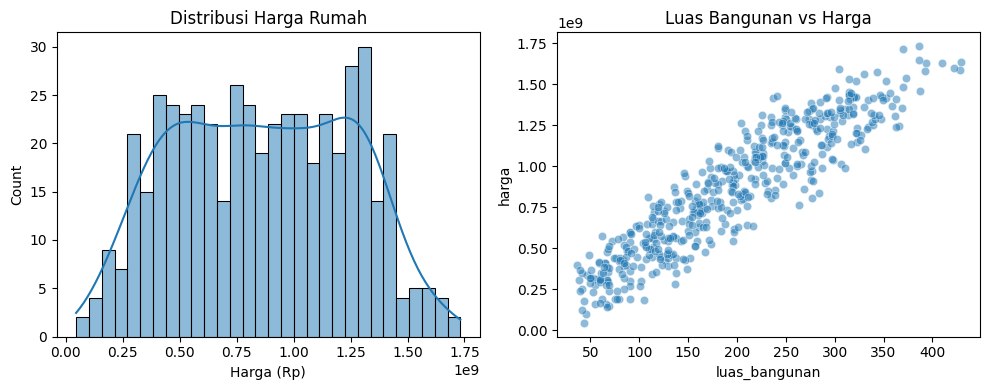

In [4]:
# Visualisasi distribusi harga
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['harga'], bins=30, kde=True)
plt.title('Distribusi Harga Rumah')
plt.xlabel('Harga (Rp)')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x='luas_bangunan', y='harga', alpha=0.5)
plt.title('Luas Bangunan vs Harga')
plt.tight_layout()
plt.show()

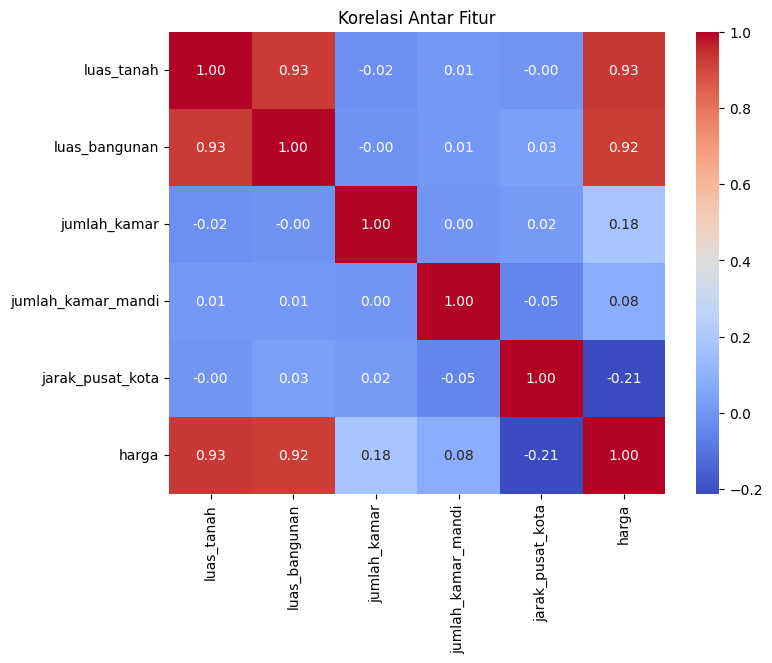

In [5]:
# Heatmap korelasi
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi Antar Fitur')
plt.show()

## 3. Preprocessing & Training Model

In [6]:
# Pisah fitur dan target
X = df.drop('harga', axis=1)
y = df['harga']

# Split train-test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f'Train size : {X_train.shape}')
print(f'Test size  : {X_test.shape}')

Train size : (400, 5)
Test size  : (100, 5)


In [7]:
# Training model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Evaluasi
y_pred = model.predict(X_test_scaled)

mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print(f'MAE  : Rp {mae:,.0f}')
print(f'RMSE : Rp {rmse:,.0f}')
print(f'R²   : {r2:.4f}')

MAE  : Rp 33,875,260
RMSE : Rp 43,850,693
R²   : 0.9863


## 4. Simpan Model & Scaler

In [8]:
# Simpan model dan scaler sebagai file .pkl
joblib.dump(model,  'model_harga_rumah.pkl')
joblib.dump(scaler, 'scaler_harga_rumah.pkl')

print('Model berhasil disimpan!')
print('File: model_harga_rumah.pkl')
print('File: scaler_harga_rumah.pkl')

Model berhasil disimpan!
File: model_harga_rumah.pkl
File: scaler_harga_rumah.pkl


## 5. Tes Load Model (Simulasi Inferensi)

In [9]:
# Simulasi data baru dari user
data_baru = pd.DataFrame([{
    'luas_tanah': 150,
    'luas_bangunan': 100,
    'jumlah_kamar': 3,
    'jumlah_kamar_mandi': 2,
    'jarak_pusat_kota': 5.0
}])

# Load ulang model dan scaler
loaded_model  = joblib.load('model_harga_rumah.pkl')
loaded_scaler = joblib.load('scaler_harga_rumah.pkl')

# Prediksi
data_scaled = loaded_scaler.transform(data_baru)
prediksi    = loaded_model.predict(data_scaled)

print(f'Prediksi Harga Rumah: Rp {prediksi[0]:,.0f}')

Prediksi Harga Rumah: Rp 585,849,206
